# Decision Trees with LEGO - DEV A

This notebook contains the developer A part of the main notebook.

### Imports

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import src.data as data
import src.plots as plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

### Constants

In [2]:
SEED = 42
N = 300
NOISE = 0.15
MAX_DEPTH = None   # no limit: on clean data the tree stops by itself at depth 3
TEST_SIZE = 0.3
CRITERION = "entropy"

## Data Helpers

Checking that the shared helpers in `src/data.py` work: data creation, balance in the dataset and depth-3 tree can express the rule.

### Data Creation

In [3]:
clean_df = data.make_data(n=N, noise=0.0, seed=SEED)
noisy_df = data.make_data(n=N, noise=NOISE, seed=SEED)
display(clean_df.head())
noisy_df.head()

,stud_rows,stud_cols,colour,accepted,accepted_true,flipped
0,1,10,pink,False,False,False
1,2,8,brown,True,True,False
2,2,2,pink,True,True,False
3,2,8,yellow,True,True,False
4,1,4,pink,False,False,False


,stud_rows,stud_cols,colour,accepted,accepted_true,flipped
0,1,10,pink,False,False,False
1,2,8,brown,True,True,False
2,2,2,pink,False,True,True
3,2,8,yellow,True,True,False
4,1,4,pink,True,False,True


### Balance Check
With this, we can check if there is around 50% acceptance rate in the clean dataset. Meaning the rule is balanced
If it is, that means we can use accuracy as a metric to evaluate the model.

In [4]:
print(f"Acceptance rate: {clean_df['accepted_true'].mean()}")

Acceptance rate: 0.5366666666666666


### Depth-3 Tree Expresses the Rule

We designed the builder's rule so that a shallow tree (`max_depth=3`) can represent it exactly.
This gives a clear favourable case for Experiment 1: the learned tree should match the true rule, and it stays small enough to read and trace from root to leaf.

This is a check on the data generator, not an evaluation. That is why we fit on all the data with
no train/test split.

In [5]:
enc = data.make_encoder()
X = enc.fit_transform(clean_df[data.FEATURES])
names = enc.get_feature_names_out()
y = clean_df["accepted_true"]

tree = DecisionTreeClassifier(criterion=CRITERION, max_depth=3, random_state=SEED).fit(X, y)
print(export_text(tree, feature_names=list(names)))

used = {names[i] for i in tree.tree_.feature if i >= 0}
print("Features used:", used)
assert tree.score(X, y) == 1.0, "Depth 3 cannot express the rule"
assert {"stud_rows", "stud_cols"} <= used and any(u.startswith("colour_") for u in used)
print("Depth-3 tree recovers the rule with all three features")

|--- stud_rows <= 1.50
|   |--- colour_yellow <= 0.50
|   |   |--- class: False
|   |--- colour_yellow >  0.50
|   |   |--- stud_cols <= 3.50
|   |   |   |--- class: False
|   |   |--- stud_cols >  3.50
|   |   |   |--- class: True
|--- stud_rows >  1.50
|   |--- colour_yellow <= 0.50
|   |   |--- class: True
|   |--- colour_yellow >  0.50
|   |   |--- stud_cols <= 3.50
|   |   |   |--- class: False
|   |   |--- stud_cols >  3.50
|   |   |   |--- class: True

Features used: {'stud_rows', 'colour_yellow', 'stud_cols'}
Depth-3 tree recovers the rule with all three features


## Plotting Helpers
Checking that the shared helpers in `src/plots.py` work: decision regions, tree diagram, feature importances and a train/test curve.

### Data Split & Model Training

In [6]:
train_df, test_df = train_test_split(clean_df, test_size=0.3, stratify=clean_df["accepted"], random_state=SEED)

enc = data.make_encoder()
X_train = enc.fit_transform(train_df[data.FEATURES])
y_train = train_df["accepted"]

tree = DecisionTreeClassifier(criterion=CRITERION, max_depth=3, random_state=SEED).fit(X_train, y_train)
print(f"train acc: {tree.score(X_train, y_train):.3f}")

train acc: 1.000


### Decision regions

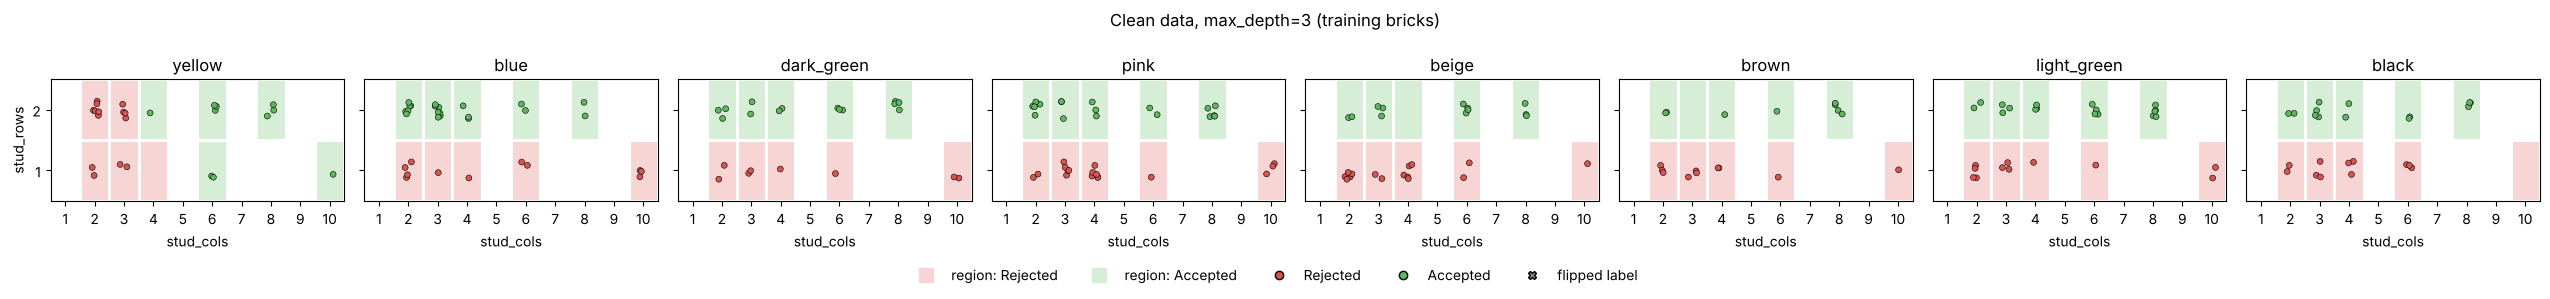

In [7]:
plots.plot_regions(tree, enc, train_df, title="Clean data, max_depth=3 (training bricks)")
plt.show()

### Tree diagram

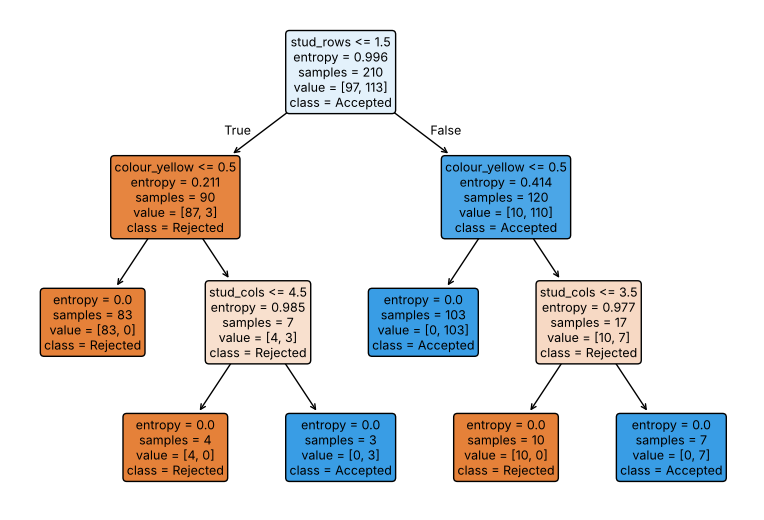

In [8]:
plots.plot_tree(tree, enc)
plt.show()

### Feature importances

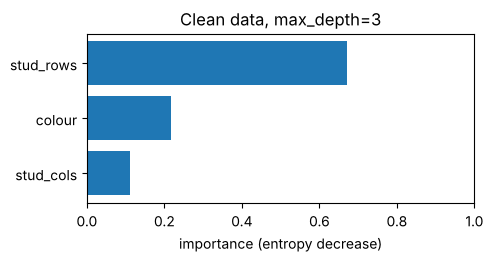

In [9]:
plots.plot_importances(tree, enc, title="Clean data, max_depth=3")
plt.show()

### Train/CV curve over depth
Scores come from 5-fold cross-validation on the training data only. The test set is not used to compare depths, to avoid lookahead bias.

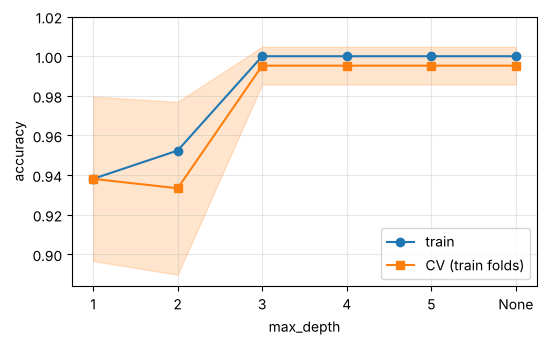

In [10]:
from sklearn.model_selection import cross_val_score

depths = [1, 2, 3, 4, 5, None]
train_acc, cv_mean, cv_std = [], [], []
for d in depths:
    t = DecisionTreeClassifier(criterion=CRITERION, max_depth=d, random_state=SEED)
    cv = cross_val_score(t, X_train, y_train, cv=5, scoring="accuracy")
    cv_mean.append(cv.mean())
    cv_std.append(cv.std())
    train_acc.append(t.fit(X_train, y_train).score(X_train, y_train))

plots.plot_curves(depths, train_acc, cv_scores=cv_mean, cv_std=cv_std, xlabel="max_depth")
plt.show()

## Experiment 1 — Favourable case
**Condition:** clean labels, N=300, stratified 70/30 split, `max_depth=None`, Entropy.

**Prediction:** We believe the model will achieve an almost perfect train and test accuracy. We expect `colour_red` near the root and all three features to be used.

_Note added after the prediction was written: the special colour changed from red to yellow to match the physical LEGO kit, and `max_depth` changed from 3 to None (on clean data both give the same tree). The prediction above is kept unedited._

### Data and Split

In [11]:
df = data.make_data(n=N, noise=0.0, seed=SEED)
train_df, test_df = train_test_split(df, test_size=TEST_SIZE, stratify=df[data.TARGET], random_state=SEED)

enc = data.make_encoder()
X_train = enc.fit_transform(train_df[data.FEATURES])
y_train = train_df[data.TARGET]
X_test  = enc.transform(test_df[data.FEATURES])
y_test  = test_df[data.TARGET]
names = list(enc.get_feature_names_out())

### Fit and Scores

In [12]:
tree1 = DecisionTreeClassifier(criterion=CRITERION, max_depth=MAX_DEPTH, random_state=SEED).fit(X_train, y_train)

train_pred = tree1.predict(X_train)
train_scores = {"accuracy": accuracy_score(y_train, train_pred),
                "macro_F1": f1_score(y_train, train_pred, average="macro")}

test_pred = tree1.predict(X_test)
test_scores = {"accuracy": accuracy_score(y_test, test_pred),
                "macro_F1": f1_score(y_test, test_pred, average="macro")}

results1 = pd.DataFrame({"train": train_scores,
                         "test":  test_scores}).T.round(3)
print(f"depth = {tree1.get_depth()}, leaves = {tree1.get_n_leaves()}")
results1

depth = 3, leaves = 6


,accuracy,macro_F1
train,1.000,1.000
test,0.989,0.989


### True Rule Vs Learned Tree

In [13]:
print(f"True rule: ({data.SPECIAL_COLOUR} AND cols >= 4) OR (not {data.SPECIAL_COLOUR} AND rows == 2)\n")
print(export_text(tree1, feature_names=names))

True rule: (yellow AND cols >= 4) OR (not yellow AND rows == 2)

|--- stud_rows <= 1.50
|   |--- colour_yellow <= 0.50
|   |   |--- class: False
|   |--- colour_yellow >  0.50
|   |   |--- stud_cols <= 4.50
|   |   |   |--- class: False
|   |   |--- stud_cols >  4.50
|   |   |   |--- class: True
|--- stud_rows >  1.50
|   |--- colour_yellow <= 0.50
|   |   |--- class: True
|   |--- colour_yellow >  0.50
|   |   |--- stud_cols <= 3.50
|   |   |   |--- class: False
|   |   |--- stud_cols >  3.50
|   |   |   |--- class: True



### Ploting the Learned Tree

#### Tree Diagram

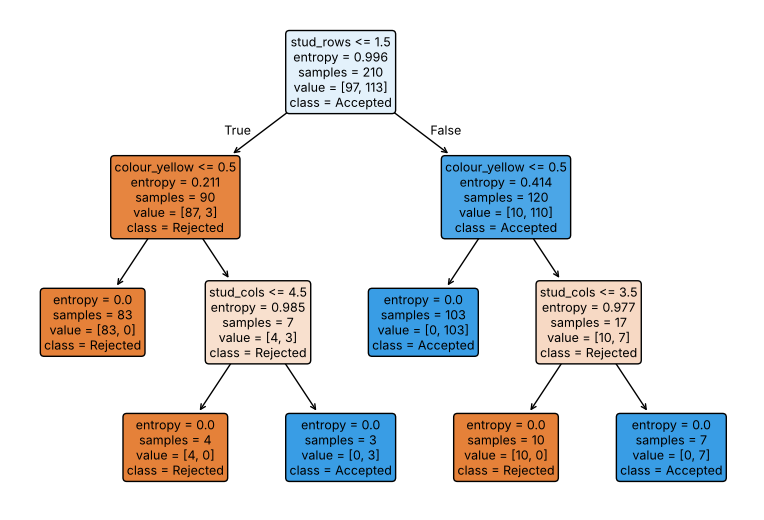

In [14]:
plots.plot_tree(tree1, enc)
plt.show()

#### Decision regions

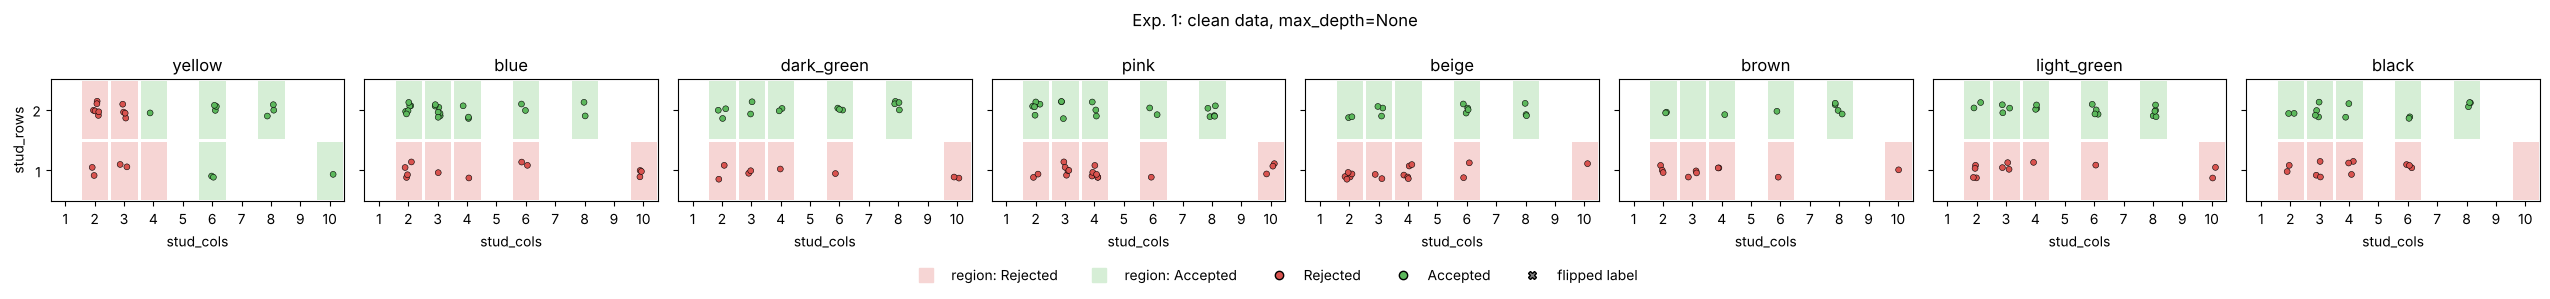

In [15]:
plots.plot_regions(tree1, enc, train_df, title="Exp. 1: clean data, max_depth=None")
plt.show()

#### Feature importances

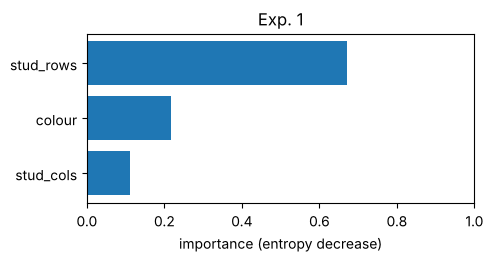

In [16]:
plots.plot_importances(tree1, enc, title="Exp. 1")
plt.show()

### Test brick trace

In [17]:
special = test_df["colour"] == data.SPECIAL_COLOUR
brick1 = test_df[special & (test_df["stud_cols"] >= 4)].head(1)    # long path -> Accepted
brick2 = test_df[~special & (test_df["stud_rows"] == 1)].head(1)   # short path -> Rejected
plots.trace(tree1, enc, brick1)
print()
plots.trace(tree1, enc, brick2)

Brick: {'stud_rows': 2, 'stud_cols': 6, 'colour': 'yellow'}
  node 0: stud_rows = 2 <= 1.50? no -> right
  node 6: colour_yellow = 1 <= 0.50? no -> right
  node 8: stud_cols = 6 <= 3.50? no -> right
  leaf 10: 7 training bricks, fractions (Rejected, Accepted) = [0. 1.] -> majority: Accepted
Prediction: Accepted | true label: Accepted

Brick: {'stud_rows': 1, 'stud_cols': 4, 'colour': 'blue'}
  node 0: stud_rows = 1 <= 1.50? yes -> left
  node 1: colour_yellow = 0 <= 0.50? yes -> left
  leaf 2: 83 training bricks, fractions (Rejected, Accepted) = [1. 0.] -> majority: Rejected
Prediction: Rejected | true label: Rejected


**What happened:** The model achieved train accuracy 1.000 and test accuracy and macro-F1 = 0.989 (1 error in 90), with 6 leaves at depth 3. Even without a depth limit, the tree stopped at depth 3 by itself, because every leaf was already pure.\
The tree recovers the structure of the rule, with one threshold off: for 1-row yellow bricks it learned `cols > 4.5` instead of `cols >= 4`. The training set had 1-row yellow bricks with 2, 3, 6 and 10 columns, but none with 4 or 5, so any threshold between 3 and 6 separates them and scikit-learn takes the midpoint. The single test error is exactly a yellow 1×4: the tree only knows the boundary where it has data close to it.\
Contrary to our prediction, the root is `stud_rows`, not the special colour (`colour_yellow`). Splitting on rows first gives the larger information gain (entropy decrease), because the "rows = 2" condition covers the 7 non-yellow colours.\
The traced yellow 2×6 goes `rows > 1.5` -> `yellow` -> `cols > 3.5` -> a pure Accepted leaf.\
The traced blue 1×4 goes `rows ≤ 1.5` -> `not yellow` -> a pure Rejected leaf.